# 02 · Manifold — principal-curve trajectory (low-cycling developmental lobe)

Steen 2021's DLBCL malignant manifold is **non-branching** and carries a proliferative confound.
On the whole manifold Gastrulation tracks the cell cycle (Gast↔cycling r ≈ −0.74) and Gast/pSom
co-variation collapses — the Kürten/Lin lobe-identity failure mode. **Scoping to the low-cycling
developmental lobe (flagged in 01)** restores the reference relationships: Gast and pSom **co-vary**
(smoothed r ≈ +0.6) and both oppose Crest (Crest↔Gast r ≈ −0.9), a single (Gast/pSom)→Crest gradient
with Crest a terminal tip — no hub radiating to competing arms. The correct topology is therefore a
**principal curve** (ElPiGraph, non-branching by construction) fit on the *original joint embedding*
of the scoped lobe — **not** a re-embedding (re-embedding an anisotropic compartment fabricates
folds). The curve is rooted at the Gast/pSom-high tip; pseudotime flows to the neural-crest terminus.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path, connected_components
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # Steen2021_Hematologic
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Steen2021_Hematologic | category: Hematologic


### Load processed manifold and scope to the developmental lobe
Keep the scoped cells on their **original joint embedding coordinates** — no re-embedding. Score the
three embryonic modules against the shared **union** control pool and graph-smooth (knn-connectivity
averaging) to read geography rather than 10x per-cell dropout.

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
dev_lobe = adata.uns['dev_lobe']
sub = adata[adata.obs['lobe'] == dev_lobe].copy()
# drop any tiny detached speck within the scoped lobe (keep the main body on its inherited UMAP coords)
um = sub.obsm['X_umap']; d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
nc, lab = connected_components(adj, directed=False); main = pd.Series(lab).value_counts().index[0]
sub = sub[lab==main].copy()
print('scoped low-cycling lobe:', sub.n_obs, 'cells (of', adata.n_obs, 'whole manifold) | cycling frac %.3f' % sub.obs['cycling'].astype(str).eq('True').mean())
xy = sub.obsm['X_umap']; c = xy - xy.mean(0); u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'scoped UMAP aspect (major/minor singular value): {s[0]/s[1]:.2f}')
sc.pp.neighbors(sub, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(sub.var_names)]
for src,lab_ in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(sub.var_names)]
    sc.tl.score_genes(sub, gene_list=g, score_name=lab_, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab_}: {g.size}/{feat[src].size} genes present')
A = (sub.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0]); A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = sub.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): sub.obs[l+'_sm'] = S[:,j]
print('raw module means (honest readout):', sub.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

scoped low-cycling lobe: 1963 cells (of 2478 whole manifold) | cycling frac 0.188
scoped UMAP aspect (major/minor singular value): 1.62
Gast: 58/81 genes present
pSom: 61/98 genes present
Crest: 80/104 genes present
raw module means (honest readout): {'Gast': -0.0659, 'pSom': -0.0102, 'Crest': 0.0426}


### Scope verification — the developmental axis is not proliferation-driven
Confirm the scope removed the cell-cycle confound: (i) the module gene sets barely overlap the
Regev–Tirosh S+G2M programme; (ii) within the scoped lobe Gast/pSom co-vary and both oppose Crest;
(iii) the whole-manifold Gast↔cycling confound is documented for contrast.

In [ ]:
s_genes = set(('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split())
g2m_genes = set(('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split())
cc = s_genes | g2m_genes
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    ov = set(feat[src]) & cc
    print(f'  {l}: {len(ov)}/{len(set(feat[src]))} module genes overlap the cell-cycle programme')
print('scoped-lobe smoothed spatial correlations:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(sub.obs[a], sub.obs[b])[0,1]:+.2f}')
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
print(f'scoped Gast_sm vs cycling r = {np.corrcoef(sub.obs["Gast_sm"], cyc)[0,1]:+.2f} (whole-manifold was ~ -0.74; scope reduces the confound)')

  Gast: 0/81 module genes overlap the cell-cycle programme
  pSom: 2/98 module genes overlap the cell-cycle programme
  Crest: 0/104 module genes overlap the cell-cycle programme
scoped-lobe smoothed spatial correlations:
  Gast_sm vs pSom_sm: r = +0.77
  Crest_sm vs Gast_sm: r = -0.86
  Crest_sm vs pSom_sm: r = -0.46
scoped Gast_sm vs cycling r = -0.58 (whole-manifold was ~ -0.74; scope reduces the confound)


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself. `epg_mu=100` is strong bending regularisation. Fold-freeness and
the 2-tip / 0-fork topology are stable across Nodes = 15/20/30 (non-branching confirmed).

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks = fold_diag(a2); print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

curve N=15: 2 tips, 0 forks | self-approach 3.00
curve N=20: 2 tips, 0 forks | self-approach 2.93
curve N=30: 2 tips, 0 forks | self-approach 2.43
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.93 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin. Pseudotime then flows to the neural-crest terminus.

In [ ]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
hi = sub.obs['Crest_sm'] >= sub.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
cyc = np.maximum(pd.to_numeric(sub.obs['g1s_score'],errors='coerce').fillna(0).values,
                 pd.to_numeric(sub.obs['g2m_score'],errors='coerce').fillna(0).values)
rho_c,_ = spearmanr(t, cyc); print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} (residual cycling gradient within the low-cycling lobe; axis is developmental, gene sets cycle-free)')

tip 0: Gast=-0.0836 pSom=-0.0199 Crest=+0.0567
tip 2: Gast=-0.0511 pSom=-0.0036 Crest=+0.0306
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.935 p=0.0e+00
  pSom_sm: rho=-0.726 p=3.6e-321
  Crest_sm: rho=+0.867 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.95 (terminal if ~1)
caveat: pseudotime vs cycling score rho = +0.54 (residual cycling gradient within the low-cycling lobe; axis is developmental, gene sets cycle-free)


### House orientation (rigid rotation, verified against pseudotime)
Rotate the scoped lobe's diagonal developmental axis to horizontal by a single rigid rotation
(distance-preserving, not a re-embedding), sign fixed so the developmental origin is on the left.
Verify: the stored `X_umap_lin` x-axis correlates strongly positively with pseudotime.

In [ ]:
xy = sub.obsm['X_umap']; c = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False); th = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th),-np.sin(-th)],[np.sin(-th),np.cos(-th)]]); xyr = c @ Rm.T
if np.corrcoef(xyr[:,0], t)[0,1] < 0: xyr[:,0] = -xyr[:,0]
sub.obsm['X_umap_lin'] = xyr
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'orientation not pseudotime-consistent ({r:.2f})'
print(f'house orientation X_umap_lin; corr(x_lin, pseudotime) = {r:+.2f} (origin left, pseudotime left->right)')

house orientation X_umap_lin; corr(x_lin, pseudotime) = +0.98 (origin left, pseudotime left->right)


### Save manifold + trajectory figure (deliverable)
House style `figsize=(3.5,1.5)`, pseudotime left→right (`X_umap_lin`), `size=30`, cividis. Fold-freeness certified numerically above.

saved manifold.h5ad + manifold.pdf | cells 1963


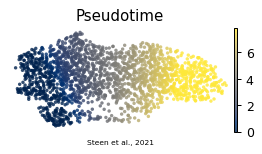

In [ ]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Steen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf | cells', sub.n_obs)